# Lab 07 – Q2: Perspective Correction (Unwarping)

### The problem in simple words
You take a photo of a **flat** thing (a paper, a screen, a painting) from the side. Because of perspective the rectangle
looks like a skewed four-sided shape: the near edge looks big, the far edge looks small.
**Goal:** turn that photo into the picture you would have got if you stood exactly in front of it ("head-on").

### How it works
1. Find the 4 corners of the object in the photo → this is the **source** (a tilted quadrilateral).
2. Decide the **destination**: a perfect rectangle `(0,0) (W,0) (W,H) (0,H)`.
3. Compute the 3×3 **homography** matrix that maps source → destination.
4. Warp the whole photo with it.

### What the task asks
> *Modify the `apply_perspective_transform` function's inputs to perform an **inverse** transformation: take the tilted view as the source and map it back to a perfect rectangle as the destination.*

The original function is a general tool: `apply_perspective_transform(image, src_points, dst_points, output_size)`.
Used **forwards** it takes a flat rectangle as source and a tilted shape as destination (it *creates* a tilted view).
To **undo** that, we only have to **swap the inputs**: *source = the tilted corners, destination = the rectangle*. That is the "inverse transformation".
Below I show both directions, prove they are inverses of each other, and then use the inverse on a realistic document photo.

In [12]:
import os, urllib.request
import numpy as np
import cv2
import matplotlib.pyplot as plt

try:   # smaller notebook file
    get_ipython().run_line_magic("config", "InlineBackend.figure_formats = ['jpeg']")
except Exception:
    pass
np.set_printoptions(precision=4, suppress=True)
os.makedirs("outputs_q2", exist_ok=True)
os.makedirs("data", exist_ok=True)

def show(images, titles, figsize=None, cols=None):
    n = len(images); cols = cols or n; rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=figsize or (5.5 * cols, 5 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, im, t in zip(axes, images, titles):
        ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB) if im.ndim == 3 else im, cmap="gray")
        ax.set_title(t, fontsize=11); ax.axis("off")
    for ax in axes[n:]: ax.axis("off")
    plt.tight_layout(); plt.show()

## 1. The function `apply_perspective_transform`
It is a thin wrapper around two OpenCV calls:
* `cv2.getPerspectiveTransform(src, dst)` → the 3×3 matrix $H$ that moves the 4 `src` points onto the 4 `dst` points,
* `cv2.warpPerspective(image, H, output_size)` → moves every pixel with $H$.

I return `H` as well, because we want to inspect and invert it.

In [13]:
def apply_perspective_transform(image, src_points, dst_points, output_size):
    '''
    Map the 4 points `src_points` of `image` onto the 4 points `dst_points`.

    image        : input picture
    src_points   : 4x2 array, where the 4 points are in the INPUT picture
    dst_points   : 4x2 array, where those 4 points must land in the OUTPUT picture
    output_size  : (width, height) of the output picture
    returns      : (warped_image, H)
    '''
    src = np.asarray(src_points, dtype=np.float32)
    dst = np.asarray(dst_points, dtype=np.float32)
    H = cv2.getPerspectiveTransform(src, dst)
    warped = cv2.warpPerspective(image, H, output_size)
    return warped, H

## 2. Forward and inverse use – a controlled experiment
First a flat chessboard-like picture (so we know exactly how the answer should look).

* **Forward:** source = rectangle corners, destination = tilted corners → we *create* a tilted view.
* **Inverse (the modification asked in the task):** source = tilted corners, destination = rectangle corners → we *undo* it.

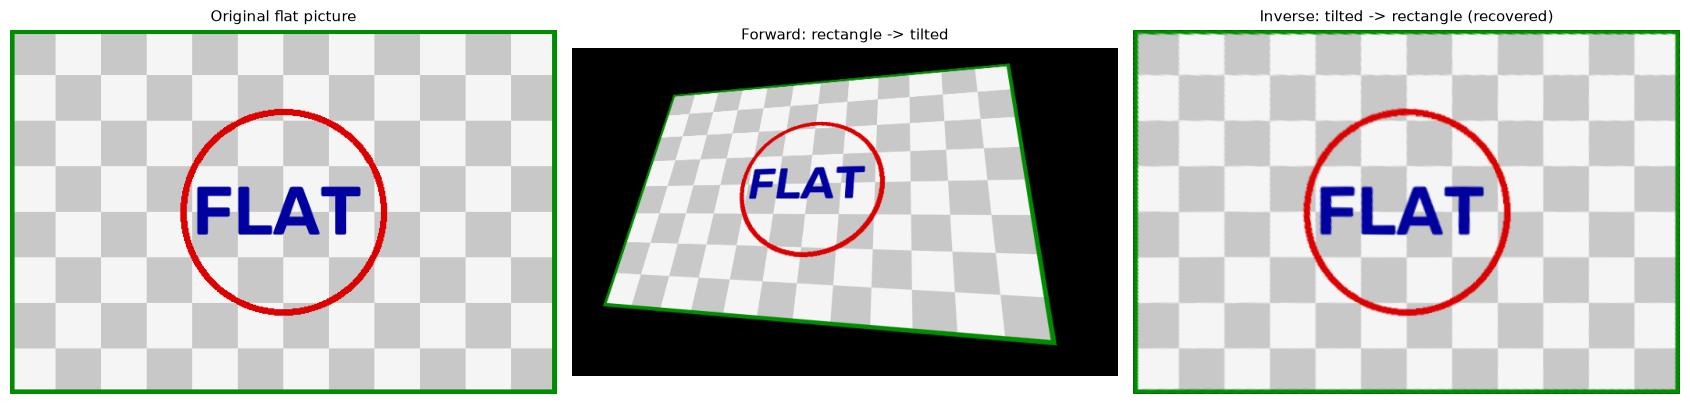

True

In [14]:
# a flat test picture with straight lines, a circle and text (so errors are easy to see)
FW, FH = 600, 400
flat = np.full((FH, FW, 3), 245, np.uint8)
for x in range(0, FW, 50):
    for y in range(0, FH, 50):
        if (x // 50 + y // 50) % 2 == 0:
            cv2.rectangle(flat, (x, y), (x + 49, y + 49), (200, 200, 200), -1)
cv2.circle(flat, (300, 200), 110, (0, 0, 220), 6)
cv2.putText(flat, "FLAT", (200, 225), cv2.FONT_HERSHEY_SIMPLEX, 2.6, (160, 0, 0), 7)
cv2.rectangle(flat, (0, 0), (FW - 1, FH - 1), (0, 140, 0), 8)

rect_pts   = [[0, 0], [FW - 1, 0], [FW - 1, FH - 1], [0, FH - 1]]       # perfect rectangle (TL, TR, BR, BL)
tilted_pts = [[130, 60], [560, 20], [620, 380], [40, 330]]                # the same 4 corners seen from an angle
CANVAS = (700, 420)

# ---- FORWARD: rectangle -> tilted  (creates a tilted view) ----
tilted_view, H_fwd = apply_perspective_transform(flat, src_points=rect_pts, dst_points=tilted_pts, output_size=CANVAS)

# ---- INVERSE: tilted -> rectangle  (only the INPUTS were changed: src and dst swapped) ----
recovered, H_inv = apply_perspective_transform(tilted_view, src_points=tilted_pts, dst_points=rect_pts, output_size=(FW, FH))

show([flat, tilted_view, recovered],
     ["Original flat picture", "Forward: rectangle -> tilted", "Inverse: tilted -> rectangle (recovered)"], figsize=(17, 4.6))
cv2.imwrite("outputs_q2/forward_tilted.png", tilted_view)
cv2.imwrite("outputs_q2/inverse_recovered.png", recovered)

In [15]:
# ---- Are the two matrices really inverses of each other? ----
print("H_forward (rectangle -> tilted):\n", H_fwd)
print("\nH_inverse (tilted -> rectangle):\n", H_inv)
print("\nH_forward @ H_inverse  (should be the identity, up to scale):\n", (H_fwd @ H_inv) / (H_fwd @ H_inv)[2, 2])
print("\nH_inverse == inv(H_forward)  (after fixing the scale)?",
      np.allclose(H_inv / H_inv[2, 2], np.linalg.inv(H_fwd) / np.linalg.inv(H_fwd)[2, 2], atol=1e-6))

# ---- How well did we recover the original? (compare only the area that was visible) ----
err = cv2.absdiff(recovered, flat)
inner = err[10:-10, 10:-10]
print("\nMean absolute error to the original picture: %.2f / 255" % inner.mean())

# ---- Same result using OpenCV's WARP_INVERSE_MAP flag (it simply uses the inverse of the matrix for you) ----
rec2 = cv2.warpPerspective(tilted_view, H_fwd, (FW, FH), flags=cv2.INTER_LINEAR | cv2.WARP_INVERSE_MAP)
print("WARP_INVERSE_MAP with the forward matrix gives the same image?", np.abs(rec2.astype(int) - recovered.astype(int)).mean() < 1.0)

H_forward (rectangle -> tilted):
 [[  0.5148  -0.2492 130.    ]
 [ -0.074    0.4814  60.    ]
 [ -0.0004  -0.0006   1.    ]]

H_inverse (tilted -> rectangle):
 [[   2.2536    0.7512 -338.0366]
 [   0.2279    2.45   -176.628 ]
 [   0.001     0.0017    1.    ]]

H_forward @ H_inverse  (should be the identity, up to scale):
 [[ 1.  0.  0.]
 [-0.  1.  0.]
 [-0.  0.  1.]]

H_inverse == inv(H_forward)  (after fixing the scale)? True

Mean absolute error to the original picture: 1.35 / 255
WARP_INVERSE_MAP with the forward matrix gives the same image? True


**What we learn:** swapping `src_points` and `dst_points` gives exactly the inverse matrix: $H_{inv} = H_{fwd}^{-1}$.
So "unwarping" = "apply the perspective transform backwards".
Small remaining differences come only from pixel interpolation and from the parts of the picture that were cut off in the tilted view.

## 3. Real use: flatten a photo of a document
Now the classic case. We do **not** know the matrix – we only have the tilted photo, so we must find the 4 corners ourselves.

Because no camera is attached to this notebook I generate a realistic "phone photo of an A4 paper lying on a desk"
(paper with text and a table, desk, pen, cup, uneven lighting, noise). If you have your own photo, set `MY_PHOTO = "your_file.jpg"` in the next cell.

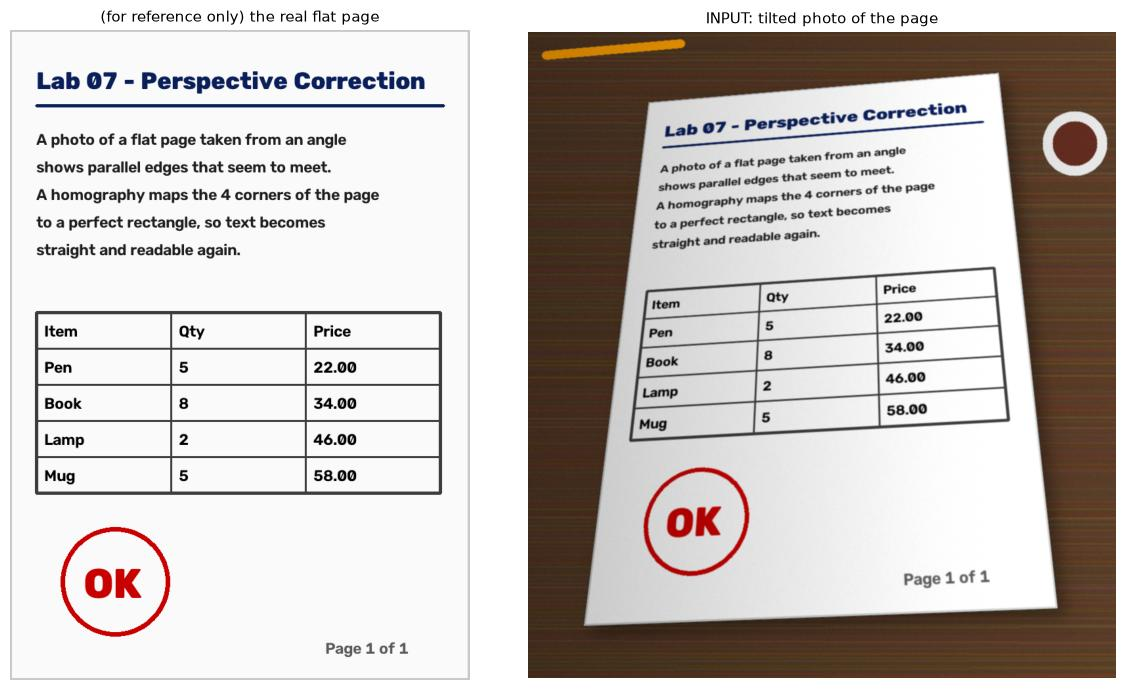

In [16]:
MY_PHOTO = None          # e.g. "my_document_photo.jpg"  -> your own picture instead of the generated one

# ----------------- build the flat A4 page (the ground truth we want to recover) -----------------
PAGE_W, PAGE_H = 700, 990                      # A4 ratio 1 : 1.414
page = np.full((PAGE_H, PAGE_W, 3), 250, np.uint8)
cv2.putText(page, "Lab 07 - Perspective Correction", (40, 90), cv2.FONT_HERSHEY_DUPLEX, 1.25, (90, 30, 10), 2)
cv2.line(page, (40, 115), (PAGE_W - 40, 115), (90, 30, 10), 3)
lines = ["A photo of a flat page taken from an angle", "shows parallel edges that seem to meet.",
         "A homography maps the 4 corners of the page", "to a perfect rectangle, so text becomes", "straight and readable again."]
for i, t in enumerate(lines):
    cv2.putText(page, t, (40, 175 + i * 42), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (30, 30, 30), 2)
# a table
x0, y0, cw, ch = 40, 430, 205, 55
for r in range(5):
    for c in range(3):
        cv2.rectangle(page, (x0 + c * cw, y0 + r * ch), (x0 + (c + 1) * cw, y0 + (r + 1) * ch), (60, 60, 60), 2)
        txt = ["Item", "Qty", "Price"][c] if r == 0 else f"{['Pen','Book','Lamp','Mug'][r-1]}" if c == 0 else str((r * 3 + c) % 9 + 1) if c == 1 else f"{r*12+c*5}.00"
        cv2.putText(page, txt, (x0 + c * cw + 12, y0 + r * ch + 37), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 0), 2)
cv2.rectangle(page, (x0, y0), (x0 + 3 * cw, y0 + 5 * ch), (60, 60, 60), 4)
cv2.circle(page, (160, 840), 80, (0, 0, 200), 6); cv2.putText(page, "OK", (112, 865), cv2.FONT_HERSHEY_DUPLEX, 2.2, (0, 0, 200), 4)
cv2.putText(page, "Page 1 of 1", (480, 950), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (90, 90, 90), 2)
cv2.rectangle(page, (0, 0), (PAGE_W - 1, PAGE_H - 1), (200, 200, 200), 3)

# ----------------- photograph it: place on a desk, view from an angle -----------------
if MY_PHOTO and os.path.exists(MY_PHOTO):
    photo = cv2.imread(MY_PHOTO)
    true_corners = None
else:
    rng = np.random.default_rng(3)
    PW, PH = 1000, 1100
    desk = np.zeros((PH, PW, 3), np.uint8); desk[:] = (35, 55, 80)
    for y in range(0, PH, 7):                                              # wood grain
        cv2.line(desk, (0, y), (PW, y + int(rng.integers(-3, 4))), (30 + int(rng.integers(0, 20)), 50 + int(rng.integers(0, 20)), 75 + int(rng.integers(0, 25))), 2)
    true_corners = np.float32([[205, 120], [800, 70], [900, 980], [95, 1010]])           # TL, TR, BR, BL of the paper in the photo
    Hp = cv2.getPerspectiveTransform(np.float32([[0, 0], [PAGE_W - 1, 0], [PAGE_W - 1, PAGE_H - 1], [0, PAGE_H - 1]]), true_corners)
    warped = cv2.warpPerspective(page, Hp, (PW, PH))
    m = cv2.warpPerspective(np.full((PAGE_H, PAGE_W), 255, np.uint8), Hp, (PW, PH))
    shadow = cv2.GaussianBlur(cv2.warpPerspective(np.full((PAGE_H, PAGE_W), 255, np.uint8), Hp, (PW, PH)), (0, 0), 14)
    desk = (desk * (1 - 0.35 * (np.roll(shadow, (14, 14), (0, 1)) / 255.0)[..., None])).astype(np.uint8)
    photo = desk.copy(); photo[m > 0] = warped[m > 0]
    cv2.circle(photo, (930, 190), 55, (210, 210, 210), -1); cv2.circle(photo, (930, 190), 38, (30, 40, 90), -1)   # a cup
    cv2.line(photo, (30, 40), (260, 20), (0, 160, 255), 14)                                                       # a pen
    gx = np.linspace(0.78, 1.12, PW)[None, :, None]                                                               # uneven light
    photo = np.clip(photo * gx + rng.normal(0, 4, photo.shape), 0, 255).astype(np.uint8)
    photo = cv2.GaussianBlur(photo, (3, 3), 0)

cv2.imwrite("outputs_q2/document_photo_input.png", photo)
show([page, photo], ["(for reference only) the real flat page", "INPUT: tilted photo of the page"], figsize=(12, 7))

### Step A – find the 4 corners automatically
The paper is much brighter than the desk, so:
1. convert to grey and blur (removes noise),
2. threshold with **Otsu** (automatic brightness cut-off) → white paper, black background,
3. close small holes, take the **largest contour** (the paper),
4. approximate that contour by a polygon – it should have **4 corners**,
5. **order** the corners as *top-left, top-right, bottom-right, bottom-left* (the order must match the destination rectangle!).

(If automatic detection fails on your own photo, you can click the corners by hand – see the optional cell further below.)

Detected corners (TL, TR, BR, BL):
 [[ 206.  122.]
 [ 799.   71.]
 [ 899.  979.]
 [  98. 1008.]]

True corners:
 [[ 205.  120.]
 [ 800.   70.]
 [ 900.  980.]
 [  95. 1010.]]
Average corner error: 2.17 pixels


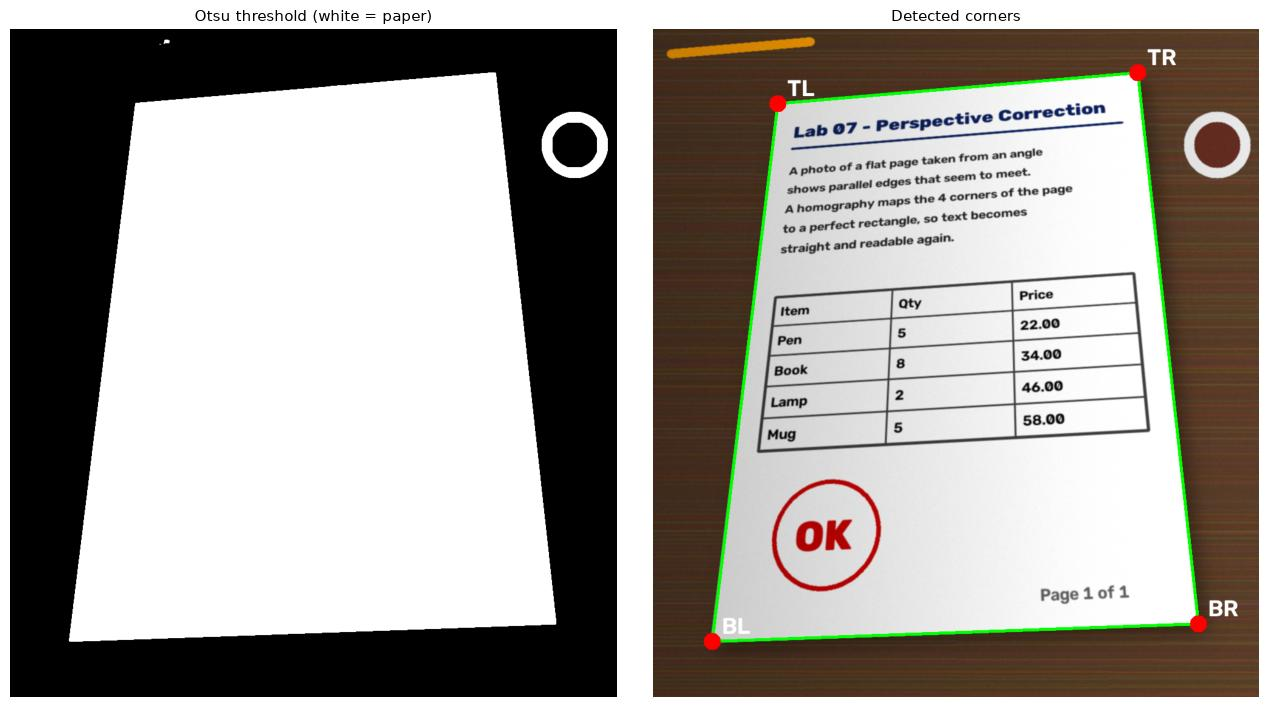

In [17]:
def order_corners(pts):
    '''Return corners as TL, TR, BR, BL.  TL has the smallest x+y, BR the largest; TR has the smallest y-x, BL the largest.'''
    pts = np.asarray(pts, dtype=np.float32).reshape(4, 2)
    s = pts.sum(axis=1)
    d = np.diff(pts, axis=1).ravel()          # y - x
    return np.array([pts[np.argmin(s)], pts[np.argmin(d)], pts[np.argmax(s)], pts[np.argmax(d)]], dtype=np.float32)

def find_document_corners(image, debug=False):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (7, 7), 0)
    _, bw = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    bw = cv2.morphologyEx(bw, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_RECT, (25, 25)))   # fill text holes
    cnts, _ = cv2.findContours(bw, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cnts = sorted(cnts, key=cv2.contourArea, reverse=True)
    best = None
    for c in cnts[:5]:
        peri = cv2.arcLength(c, True)
        approx = cv2.approxPolyDP(c, 0.02 * peri, True)
        if len(approx) == 4 and cv2.contourArea(approx) > 0.1 * image.shape[0] * image.shape[1]:
            best = approx; break
    if best is None:                                   # fallback: use the minimum-area rectangle of the biggest blob
        best = cv2.boxPoints(cv2.minAreaRect(cnts[0]))
    corners = order_corners(best)
    return (corners, bw) if debug else corners

corners, mask_bw = find_document_corners(photo, debug=True)
print("Detected corners (TL, TR, BR, BL):\n", corners)
if true_corners is not None:
    print("\nTrue corners:\n", true_corners)
    print("Average corner error: %.2f pixels" % np.linalg.norm(corners - true_corners, axis=1).mean())

vis = photo.copy()
cv2.polylines(vis, [corners.astype(np.int32)], True, (0, 255, 0), 4)
for name, (x, y) in zip(["TL", "TR", "BR", "BL"], corners):
    cv2.circle(vis, (int(x), int(y)), 14, (0, 0, 255), -1)
    cv2.putText(vis, name, (int(x) + 16, int(y) - 12), cv2.FONT_HERSHEY_SIMPLEX, 1.3, (255, 255, 255), 4)
show([mask_bw, vis], ["Otsu threshold (white = paper)", "Detected corners"], figsize=(13, 7))

### Step B – choose the size of the destination rectangle
We need to know how big the flat picture should be.
* **From the corners:** width = the longer of the top/bottom edge, height = the longer of the left/right edge.
* **From the known paper shape:** if you know it is an A4 sheet (ratio 1 : 1.414) it is better to *force* that ratio, because perspective distorts edge lengths.

In [18]:
def output_size_from_corners(c):
    tl, tr, br, bl = c
    width  = int(round(max(np.linalg.norm(tr - tl), np.linalg.norm(br - bl))))
    height = int(round(max(np.linalg.norm(bl - tl), np.linalg.norm(br - tr))))
    return width, height

W_auto, H_auto = output_size_from_corners(corners)
W_a4 = W_auto
H_a4 = int(round(W_auto * 1.414))
print("Size from the corners  :", (W_auto, H_auto))
print("Size with forced A4 1:1.414 :", (W_a4, H_a4))

Size from the corners  : (802, 913)
Size with forced A4 1:1.414 : (802, 1134)


### Step C – the INVERSE transformation (tilted view = source, perfect rectangle = destination)
This is exactly the modification asked in the task: we call the **same** `apply_perspective_transform`, but
`src_points` = the detected tilted corners and `dst_points` = the corners of a perfect rectangle.

Homography used (tilted -> rectangle):
 [[   1.5126    0.1844 -334.0931]
 [   0.1601    1.8615 -260.0791]
 [   0.0001    0.0004    1.    ]]


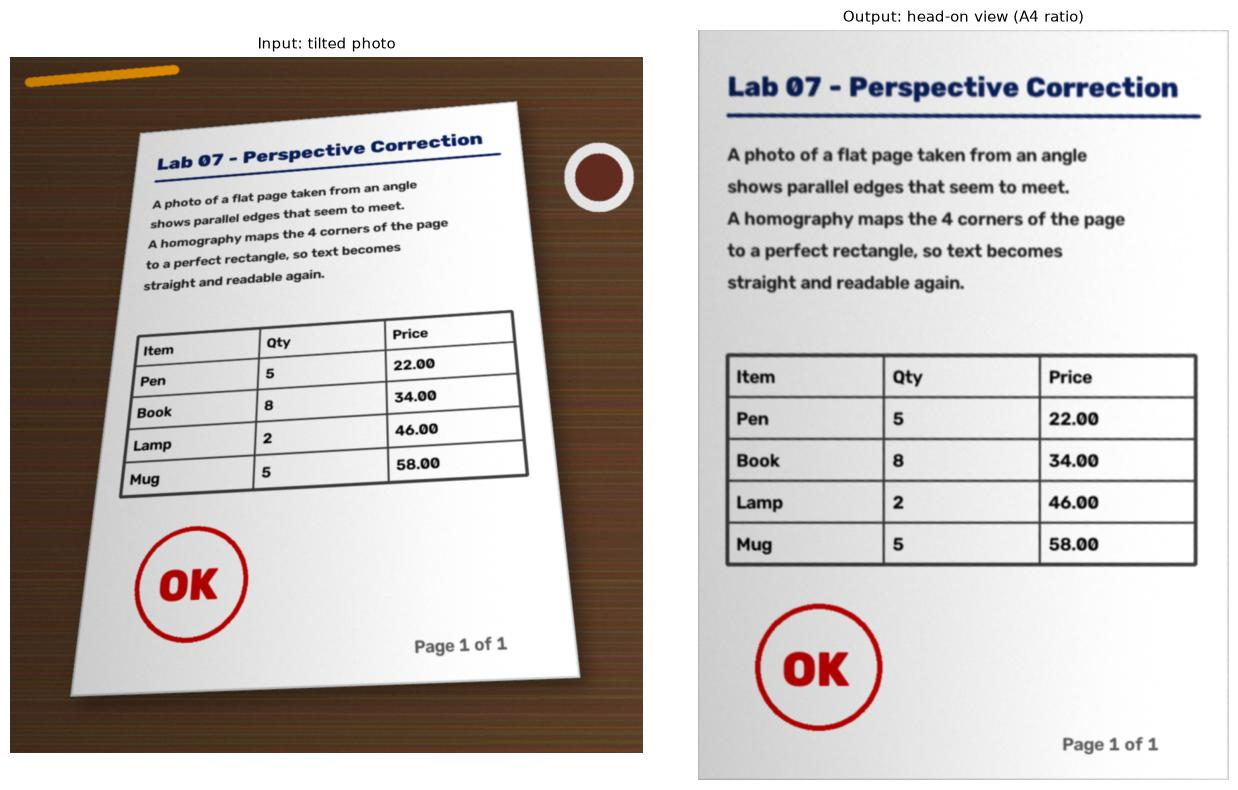

In [19]:
def unwarp(image, tilted_corners, out_w, out_h):
    # INVERSE transformation:   source = tilted view,   destination = perfect rectangle
    rectangle = [[0, 0], [out_w - 1, 0], [out_w - 1, out_h - 1], [0, out_h - 1]]
    return apply_perspective_transform(image, src_points=tilted_corners, dst_points=rectangle, output_size=(out_w, out_h))

result_auto, H_auto_mat = unwarp(photo, corners, W_auto, H_auto)
result_a4,   H_a4_mat   = unwarp(photo, corners, W_a4, H_a4)
print("Homography used (tilted -> rectangle):\n", H_a4_mat)
cv2.imwrite("outputs_q2/document_unwarped_auto_size.png", result_auto)
cv2.imwrite("outputs_q2/document_unwarped_A4.png", result_a4)

show([photo, result_a4], ["Input: tilted photo", "Output: head-on view (A4 ratio)"], figsize=(13, 8))

Mean absolute difference to the true page (lighting removed): 11.2 grey levels (0 = identical, 255 = worst)
Share of pixels that differ by more than 60 grey levels: 6.00 %

Same test with the TRUE corners (perfect detection): mean 6.9, share >60: 1.29 %
-> a part of the error is the ~2 px corner error (thin letters shift a little);
   the rest is blur + noise + resampling of the simulated photo, which no geometry step can undo.


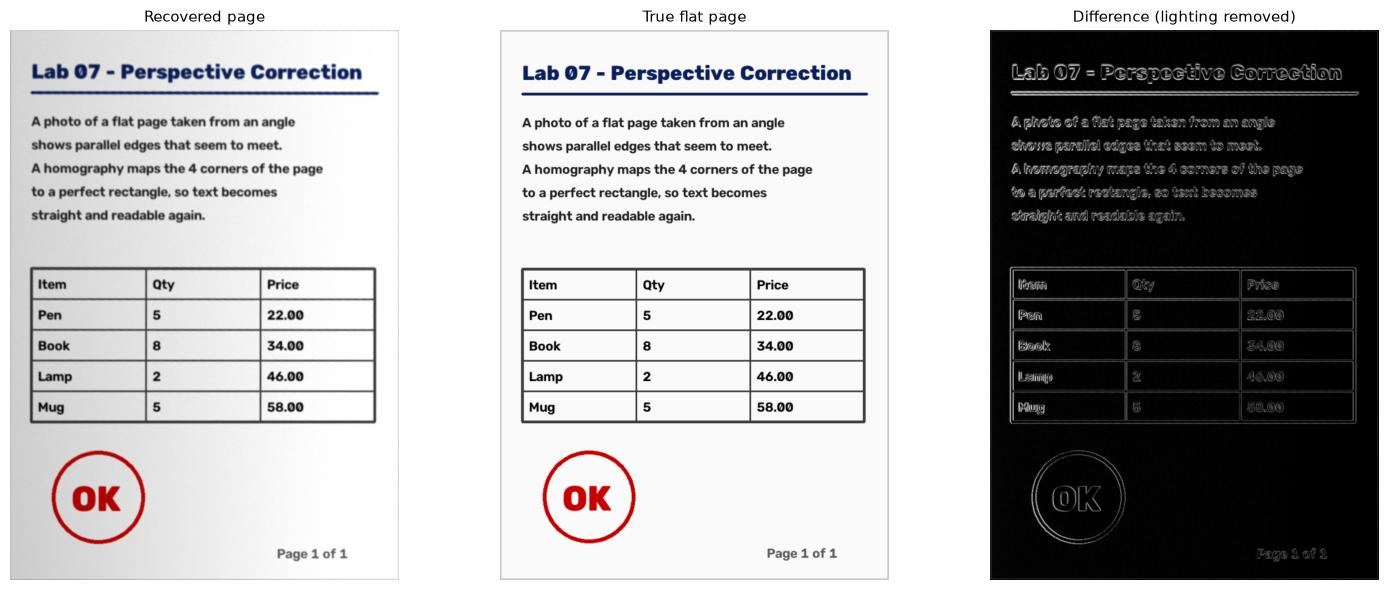

In [20]:
# ---- How close is the result to the real flat page? (we only know the real page because we generated it) ----
if MY_PHOTO is None:
    ref = cv2.resize(page, (W_a4, H_a4), interpolation=cv2.INTER_AREA)
    def flat_field(img_bgr):
        # remove the uneven lighting: divide by a heavily blurred copy of the picture (the "light map")
        g = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY).astype(np.float32)
        light = cv2.GaussianBlur(cv2.dilate(g, np.ones((25, 25), np.uint8)), (0, 0), 30)
        return np.clip(g / light * 250, 0, 255)
    g1, g2 = flat_field(result_a4), flat_field(ref)
    diff = np.abs(g1 - g2)
    inner = diff[20:-20, 20:-20]                      # ignore the 20 px page border (edge pixels blend with the desk)
    print("Mean absolute difference to the true page (lighting removed): %.1f grey levels (0 = identical, 255 = worst)" % inner.mean())
    print("Share of pixels that differ by more than 60 grey levels: %.2f %%" % (100 * (inner > 60).mean()))

    # How much of this is caused by our corner detection (about 2 px off)?  Repeat with the TRUE corners.
    res_true, _ = unwarp(photo, true_corners, W_a4, H_a4)
    inner_t = np.abs(flat_field(res_true) - g2)[20:-20, 20:-20]
    print("\nSame test with the TRUE corners (perfect detection): mean %.1f, share >60: %.2f %%" % (inner_t.mean(), 100 * (inner_t > 60).mean()))
    print("-> a part of the error is the ~2 px corner error (thin letters shift a little);")
    print("   the rest is blur + noise + resampling of the simulated photo, which no geometry step can undo.")
    show([result_a4, ref, diff.astype(np.uint8)],
         ["Recovered page", "True flat page", "Difference (lighting removed)"], figsize=(15, 6))

### Straightness check
In the photo the left and right edges of the paper are not parallel (they lean towards each other).
After the correction they must be parallel and the four corners must be 90°.

In [21]:
def corner_angles(c):
    out = []
    for i in range(4):
        a, b = c[i - 1] - c[i], c[(i + 1) % 4] - c[i]
        out.append(float(np.degrees(np.arccos(a @ b / (np.linalg.norm(a) * np.linalg.norm(b))))))
    return [round(v, 1) for v in out]

after = cv2.perspectiveTransform(corners.reshape(-1, 1, 2), H_a4_mat).reshape(-1, 2)
print("Corner angles BEFORE (in the photo):", corner_angles(corners))
print("Corner angles AFTER  (corrected)   :", corner_angles(after))

def edge_dirs(c):
    return np.degrees(np.arctan2(c[3, 1] - c[0, 1], c[3, 0] - c[0, 0])), np.degrees(np.arctan2(c[2, 1] - c[1, 1], c[2, 0] - c[1, 0]))
l0, r0 = edge_dirs(corners); l1, r1 = edge_dirs(after)
print("Left vs right edge direction  before: %.1f deg vs %.1f deg (difference %.1f)" % (l0, r0, abs(l0 - r0)))
print("Left vs right edge direction  after : %.1f deg vs %.1f deg (difference %.1f)" % (l1, r1, abs(l1 - r1)))

Corner angles BEFORE (in the photo): [101.9, 91.4, 85.8, 81.0]
Corner angles AFTER  (corrected)   : [90.0, 90.0, 90.0, 90.0]
Left vs right edge direction  before: 96.9 deg vs 83.7 deg (difference 13.2)
Left vs right edge direction  after : 90.0 deg vs 90.0 deg (difference 0.0)


## 4. A second example – a painting on a wall
The same two functions work for any flat object. Here a "painting" (a photo of a castle in a frame) hangs on a wall and is photographed from the left.
This time I give the four corners by hand (as if you had clicked them), to show the manual workflow.

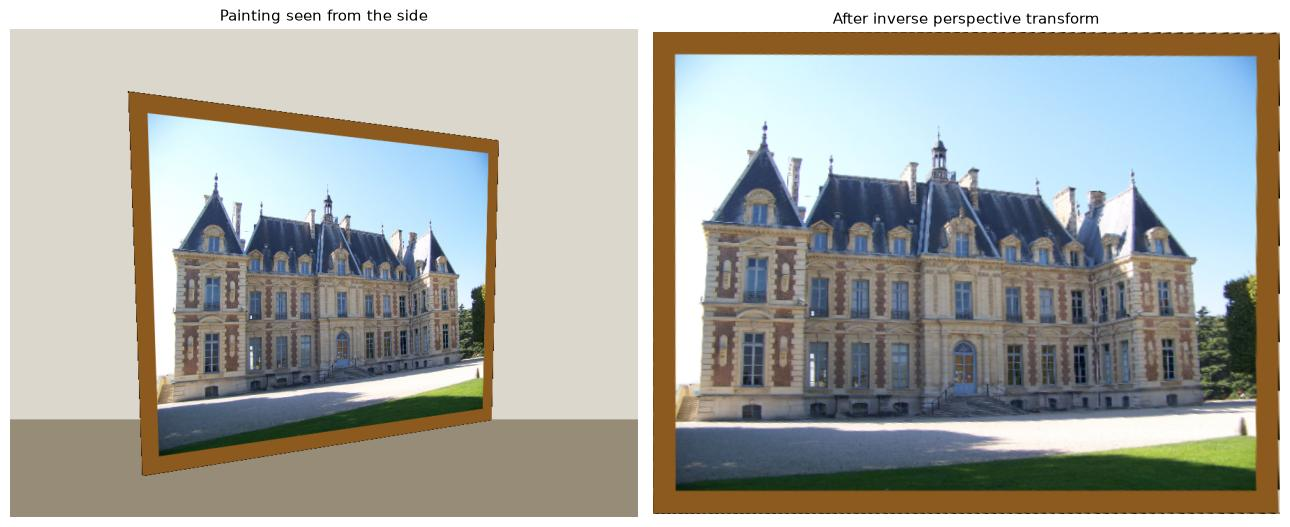

True

In [22]:
URL = "https://raw.githubusercontent.com/openMVG/ImageDataset_SceauxCastle/master/images/100_7101.JPG"
if not os.path.exists("data/painting.jpg"):
    try:
        urllib.request.urlretrieve(URL, "data/painting.jpg")
    except Exception as e:
        print("download failed:", e)
art = cv2.imread("data/painting.jpg")
if art is None:
    art = flat.copy()
art = cv2.resize(art, (640, 480))
art = cv2.copyMakeBorder(art, 25, 25, 25, 25, cv2.BORDER_CONSTANT, value=(30, 90, 140))     # wooden frame

wall = np.full((700, 900, 3), (205, 215, 220), np.uint8)
cv2.rectangle(wall, (0, 560), (900, 700), (120, 140, 150), -1)                              # floor line
frame_corners = np.float32([[170, 90], [700, 160], [690, 560], [190, 640]])                 # picture seen from the left
Hw = cv2.getPerspectiveTransform(np.float32([[0, 0], [art.shape[1] - 1, 0], [art.shape[1] - 1, art.shape[0] - 1], [0, art.shape[0] - 1]]), frame_corners)
w_art = cv2.warpPerspective(art, Hw, (900, 700)); mk = cv2.warpPerspective(np.full(art.shape[:2], 255, np.uint8), Hw, (900, 700))
wall_photo = wall.copy(); wall_photo[mk > 0] = w_art[mk > 0]

clicked = frame_corners + np.random.default_rng(1).normal(0, 1.0, (4, 2)).astype(np.float32)    # a human clicks with ~1 px error
art_w, art_h = art.shape[1], art.shape[0]
fixed, _ = unwarp(wall_photo, clicked, art_w, art_h)
show([wall_photo, fixed], ["Painting seen from the side", "After inverse perspective transform"], figsize=(13, 5.5))
cv2.imwrite("outputs_q2/painting_unwarped.png", fixed)

## 5. (Optional) Click the corners yourself
This function opens a window on **your** computer (it cannot run in a cloud/headless notebook, so it is only defined here, not executed).
Left-click the 4 corners in the order **top-left → top-right → bottom-right → bottom-left**, then press any key.
```python
def pick_corners(image, max_width=1000):
    s = min(1.0, max_width / image.shape[1]); small = cv2.resize(image, None, fx=s, fy=s)
    pts = []
    def on_mouse(event, x, y, flags, param):
        if event == cv2.EVENT_LBUTTONDOWN and len(pts) < 4:
            pts.append([x / s, y / s]); cv2.circle(small, (x, y), 6, (0, 0, 255), -1); cv2.imshow("pick 4 corners", small)
    cv2.imshow("pick 4 corners", small); cv2.setMouseCallback("pick 4 corners", on_mouse)
    while len(pts) < 4 and cv2.waitKey(50) == -1: pass
    cv2.destroyAllWindows()
    return order_corners(pts)
# corners = pick_corners(cv2.imread("my_photo.jpg"))
```

---
## Summary
| Step | What we did |
|---|---|
| Forward use of `apply_perspective_transform` | source = rectangle, destination = tilted shape → *creates* a tilted view |
| **Inverse use (the task)** | **source = tilted corners, destination = perfect rectangle → *removes* the tilt** |
| Matrix relation | $H_{inverse} = H_{forward}^{-1}$ (checked numerically) |
| Corner finding | Otsu threshold → largest contour → 4-point polygon → order TL, TR, BR, BL |
| Result | Parallel edges are parallel again, corners are 90°, text is straight and readable |

**Important detail:** the corner order of `src_points` and `dst_points` must match (TL↔TL, TR↔TR …), otherwise the picture comes out flipped or twisted.